In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

In [57]:
# Load the Stock Flow dataset
StackFlow=pd.read_csv('results.csv')

In [58]:
# overview of the dataset
StackFlow.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), object(100)
memory usage: 56.9+ MB


In [59]:
# overview of the data
list(StackFlow)

['ResponseId',
 'MainBranch',
 'Age',
 'Employment',
 'RemoteWork',
 'Check',
 'CodingActivities',
 'EdLevel',
 'LearnCode',
 'LearnCodeOnline',
 'TechDoc',
 'YearsCode',
 'YearsCodePro',
 'DevType',
 'OrgSize',
 'PurchaseInfluence',
 'BuyNewTool',
 'BuildvsBuy',
 'TechEndorse',
 'Country',
 'Currency',
 'CompTotal',
 'LanguageHaveWorkedWith',
 'LanguageWantToWorkWith',
 'LanguageAdmired',
 'DatabaseHaveWorkedWith',
 'DatabaseWantToWorkWith',
 'DatabaseAdmired',
 'PlatformHaveWorkedWith',
 'PlatformWantToWorkWith',
 'PlatformAdmired',
 'WebframeHaveWorkedWith',
 'WebframeWantToWorkWith',
 'WebframeAdmired',
 'EmbeddedHaveWorkedWith',
 'EmbeddedWantToWorkWith',
 'EmbeddedAdmired',
 'MiscTechHaveWorkedWith',
 'MiscTechWantToWorkWith',
 'MiscTechAdmired',
 'ToolsTechHaveWorkedWith',
 'ToolsTechWantToWorkWith',
 'ToolsTechAdmired',
 'NEWCollabToolsHaveWorkedWith',
 'NEWCollabToolsWantToWorkWith',
 'NEWCollabToolsAdmired',
 'OpSysPersonal use',
 'OpSysProfessional use',
 'OfficeStackAsyncHa

In [60]:
# Selecting the attributes that could be important for job satisfaction
JobSat = StackFlow[["JobSat","OrgSize","Age","Industry","Country"]]

In [61]:
auswahl = ["Germany", "United States of America"]
JobSat = JobSat[JobSat["Country"].isin(auswahl)]

In [63]:
# Adaptation of the data so that it can be evaluated
JobSat=JobSat.replace({"Age":{"Under 18 years old":1,"18-24 years old":2,"25-34 years old":3,"35-44 years old":4,"45-54 years old":5,"55-64 years old":6,"65 years or older":7,"Prefer not to say":8}})
JobSat=JobSat.replace({"OrgSize":{"Just me - I am a freelancer, sole proprietor, etc.":1,"2 to 9 employees":2,"10 to 19 employees":3,"20 to 99 employees":4,"100 to 499 employees":5,"500 to 999 employees":6,"1,000 to 4,999 employees":7,"5,000 to 9,999 employees":8,"10,000 or more employees":9,"I don’t know":10}})
JobSat=JobSat.replace({"Industry":{"Software Development":1,"Computer Systems Design and Services":2,"Internet, Telecomm or Information Services":3,"Fintech":4,"Energy":5,"Government":6,"Banking/Financial Services":7,"Manufacturing":8,"Transportation, or Supply Chain":9,"Healthcare":10,"Retail and Consumer Services":11,"Higher Education":12,"Media & Advertising Services":13,"Insurance":14,"Other:":15}})

In [64]:
# Data wrangling 
JobSat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16042 entries, 0 to 65435
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   JobSat    8123 non-null   float64
 1   OrgSize   12893 non-null  float64
 2   Age       16042 non-null  int64  
 3   Industry  8067 non-null   float64
 4   Country   16042 non-null  object 
dtypes: float64(3), int64(1), object(1)
memory usage: 752.0+ KB


In [65]:
# Data wrangling
JobSat.head(5)

,JobSat,OrgSize,Age,Industry,Country
0,NaN,NaN,1,NaN,United States of America
5,NaN,NaN,1,NaN,United States of America
6,NaN,NaN,4,NaN,United States of America
10,8.0,NaN,4,10.0,United States of America
12,8.0,NaN,4,1.0,United States of America


In [66]:
# Data wrangling
JobSat.describe()

,JobSat,OrgSize,Age,Industry
count,8123.000000,12893.000000,16042.000000,8067.000000
mean,6.914810,5.524083,3.608528,6.578778
std,2.155922,2.475818,1.366861,5.180844
min,0.000000,1.000000,1.000000,1.000000
25%,6.000000,4.000000,3.000000,1.000000
50%,7.000000,5.000000,3.000000,6.000000
75%,8.000000,7.000000,4.000000,11.000000
max,10.000000,10.000000,8.000000,15.000000


In [67]:
# Data wrangling
JobSat.isna().sum()

JobSat      7919
OrgSize     3149
Age            0
Industry    7975
Country        0
dtype: int64

In [68]:
# Data wrangling
JobSat=JobSat.dropna()

In [69]:
# Data wrangling
JobSat.isna().sum()

JobSat      0
OrgSize     0
Age         0
Industry    0
Country     0
dtype: int64

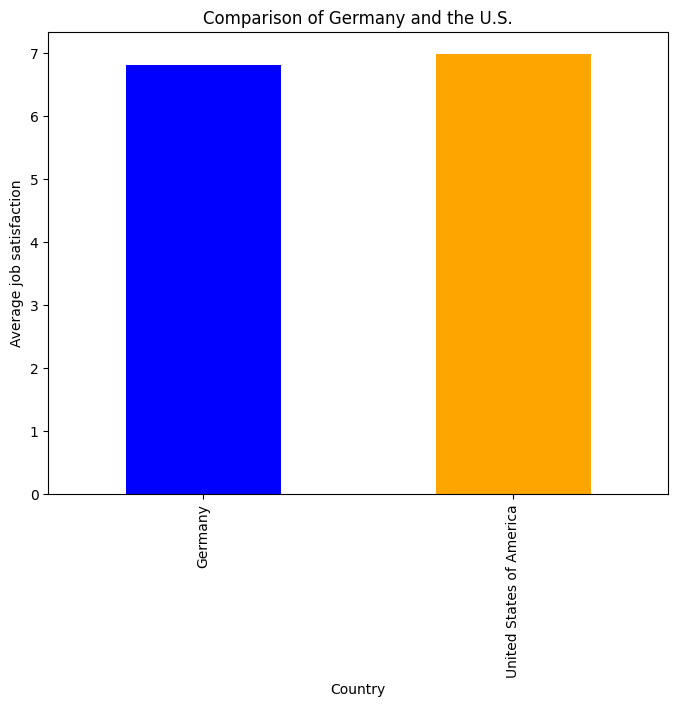

In [70]:
laender = ["Germany", "United States of America"]
gefiltert = JobSat[JobSat["Country"].isin(laender)]
mittelwerte = gefiltert.groupby("Country")["JobSat"].mean()
plt.figure(figsize=(8, 6))
mittelwerte.plot(kind="bar", color=["blue", "orange"])
plt.ylabel("Average job satisfaction")
plt.title("Comparison of Germany and the U.S.")
plt.show()

/tmp/ipykernel_13/2101653557.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Just me - I am a freelancer", "2 to 9 employees", "10 to 19 employees","20 to 99 employees", "100 to 499 employees","500 to 999 employees","1,000 to 4,999 employees", "5,000 to 9,999 employees","10,000 or more employees","I don’t know"],rotation=90 ,fontsize=10)


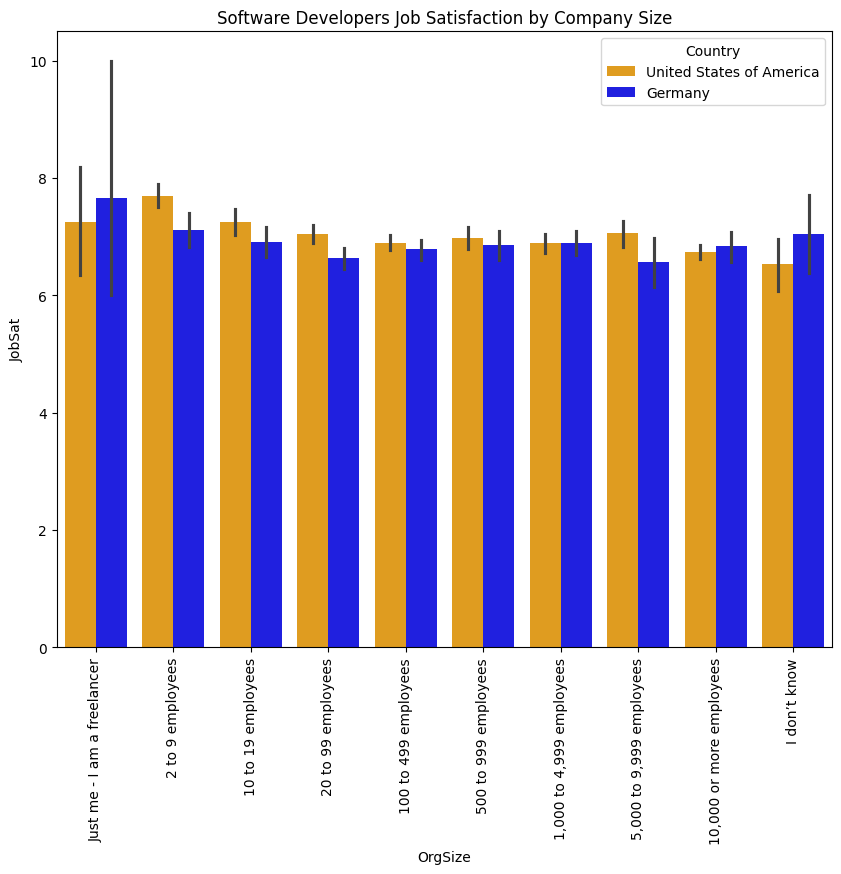

In [71]:
# Job Satisfaction by OrgSize plot
df=JobSat
plt.figure(figsize=(10, 8))
ax=sns.barplot(x = 'OrgSize',
            y = 'JobSat',
            hue = 'Country',
            data = df,
            palette = ["orange", "blue"])
ax.set_xticklabels(["Just me - I am a freelancer", "2 to 9 employees", "10 to 19 employees","20 to 99 employees", "100 to 499 employees","500 to 999 employees","1,000 to 4,999 employees", "5,000 to 9,999 employees","10,000 or more employees","I don’t know"],rotation=90 ,fontsize=10)
plt.title('Software Developers Job Satisfaction by Company Size')
plt.show()


/tmp/ipykernel_13/576611247.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Under 18 years old", "18-24 years old", "25-34 years old","35-44 years old", "45-54 years old","55-64 years old","65 years or older", "Prefer not to say"],rotation=90 ,fontsize=10)


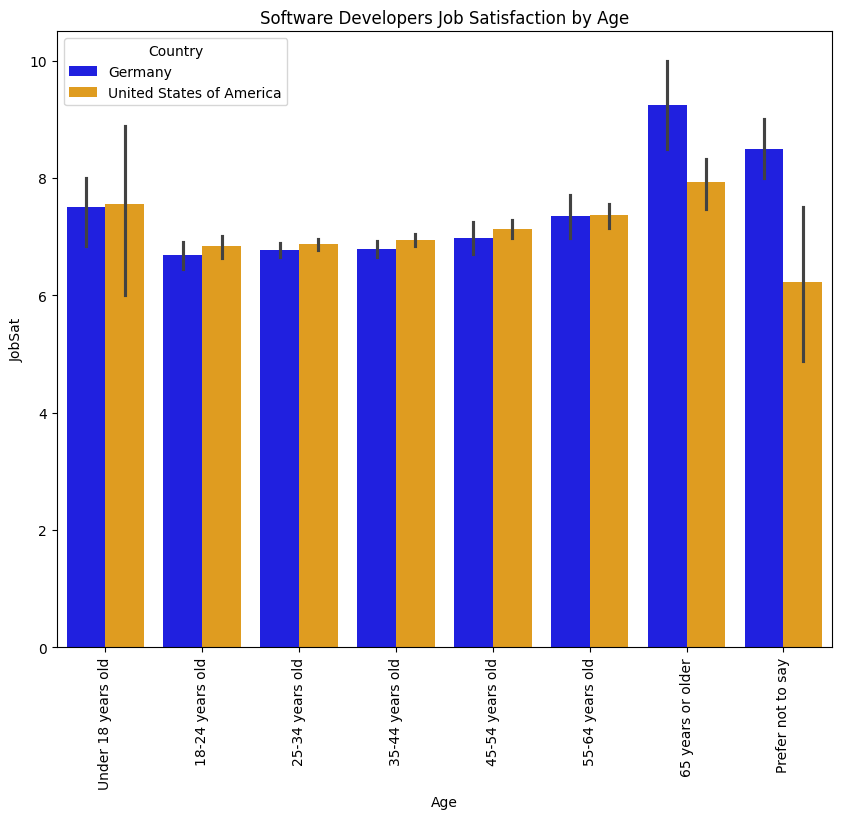

In [72]:
# Job Satisfaction by Age plot
df=JobSat
plt.figure(figsize=(10, 8))
ax=sns.barplot(x = 'Age',
            y = 'JobSat',
            hue = 'Country',
            data = df,
            palette = ["blue", "orange"])
ax.set_xticklabels(["Under 18 years old", "18-24 years old", "25-34 years old","35-44 years old", "45-54 years old","55-64 years old","65 years or older", "Prefer not to say"],rotation=90 ,fontsize=10)
plt.title('Software Developers Job Satisfaction by Age')
plt.show()

/tmp/ipykernel_13/1252289943.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Software Development", "Computer Systems Design and Services", "Internet, Telecomm or Information Services","Fintech", "Energy","Government","Banking/Financial Services", "Manufacturing","Transportation, or Supply Chain","Healthcare","Retail and Consumer Services","Higher Education","Media & Advertising Services","Insurance","Other:"],rotation=90 ,fontsize=10)


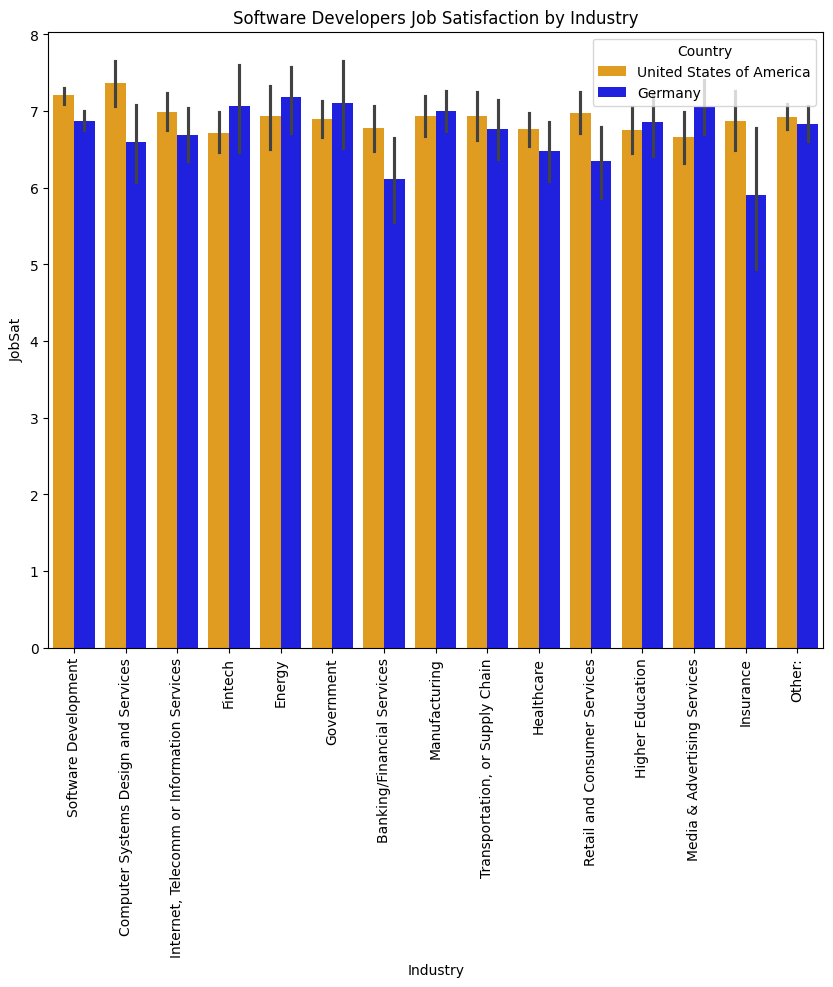

In [73]:
# Job Satisfaction by Industry plot
df=JobSat
plt.figure(figsize=(10, 8))
ax=sns.barplot(x = 'Industry',
            y = 'JobSat',
            hue = 'Country',
            data = df,
            palette = ["orange", "blue"])
ax.set_xticklabels(["Software Development", "Computer Systems Design and Services", "Internet, Telecomm or Information Services","Fintech", "Energy","Government","Banking/Financial Services", "Manufacturing","Transportation, or Supply Chain","Healthcare","Retail and Consumer Services","Higher Education","Media & Advertising Services","Insurance","Other:"],rotation=90 ,fontsize=10)
plt.title('Software Developers Job Satisfaction by Industry')
plt.show()

/tmp/ipykernel_13/1252289943.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Software Development", "Computer Systems Design and Services", "Internet, Telecomm or Information Services","Fintech", "Energy","Government","Banking/Financial Services", "Manufacturing","Transportation, or Supply Chain","Healthcare","Retail and Consumer Services","Higher Education","Media & Advertising Services","Insurance","Other:"],rotation=90 ,fontsize=10)


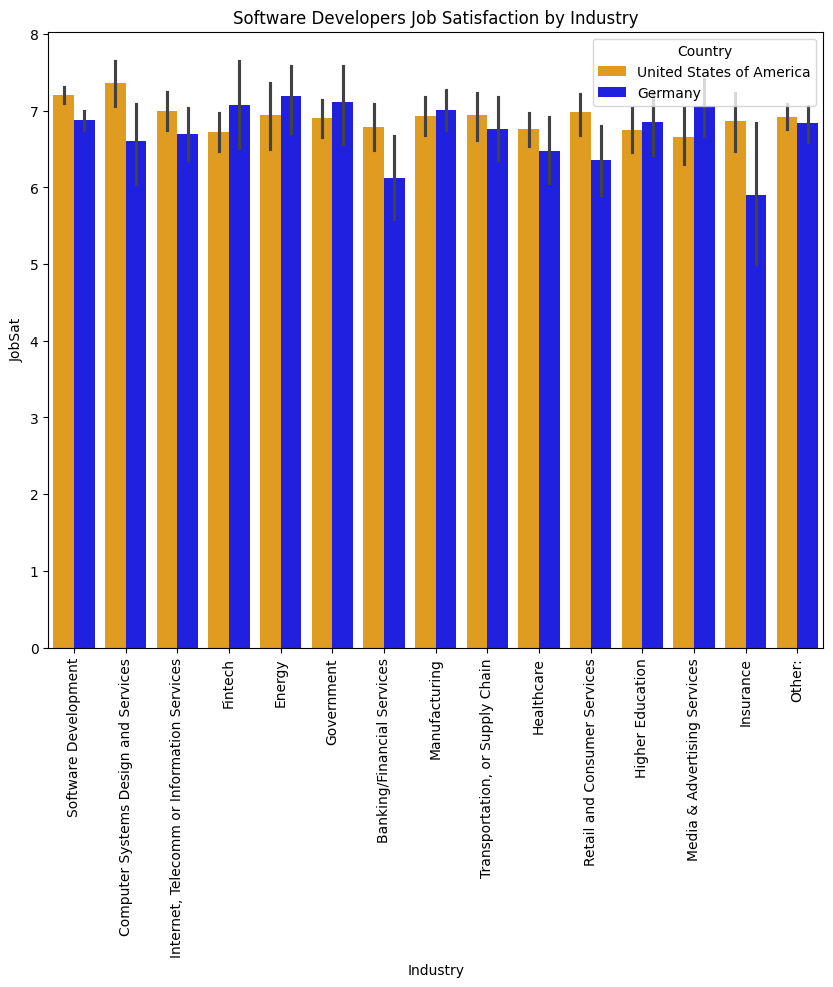

In [74]:
# Job Satisfaction by Industry plot
df=JobSat
plt.figure(figsize=(10, 8))
ax=sns.barplot(x = 'Industry',
            y = 'JobSat',
            hue = 'Country',
            data = df,
            palette = ["orange", "blue"])
ax.set_xticklabels(["Software Development", "Computer Systems Design and Services", "Internet, Telecomm or Information Services","Fintech", "Energy","Government","Banking/Financial Services", "Manufacturing","Transportation, or Supply Chain","Healthcare","Retail and Consumer Services","Higher Education","Media & Advertising Services","Insurance","Other:"],rotation=90 ,fontsize=10)
plt.title('Software Developers Job Satisfaction by Industry')
plt.show()

In [75]:
# Export the relvant data
export_csv = JobSat.to_csv ('JobSatisfaction_reduced.csv',index=False,header=True)

In [76]:
JobSat=JobSat.replace({"Country":{"Germany":1,"United States of America":2}})

/tmp/ipykernel_13/3036127609.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  JobSat=JobSat.replace({"Country":{"Germany":1,"United States of America":2}})


In [77]:
# Correlation JobSat
corr_JobSat = JobSat.corr()

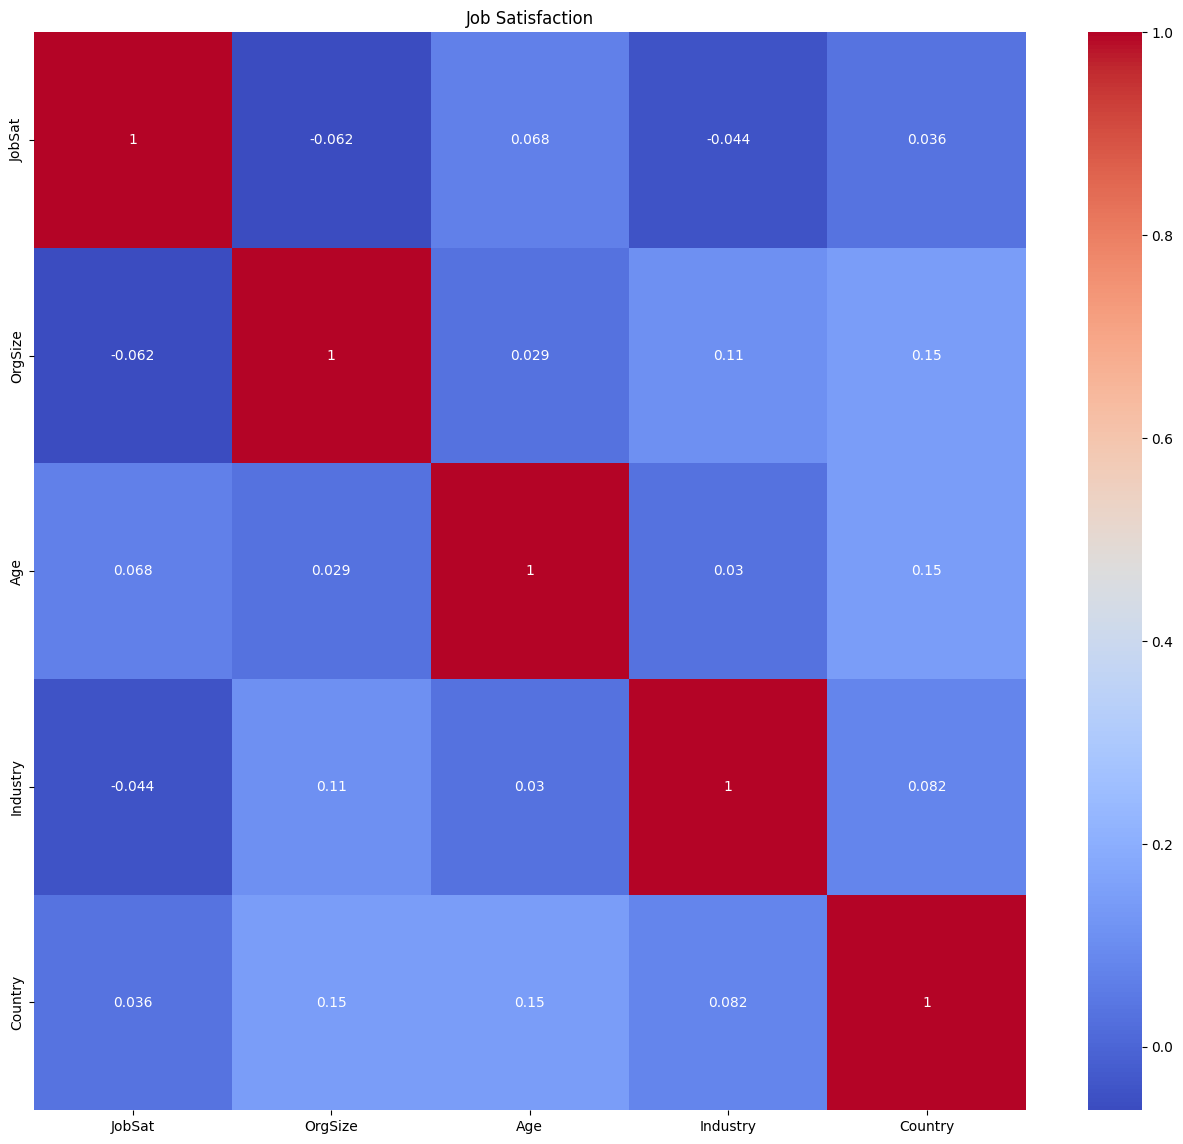

In [78]:
# Heatmap for a better overview
plt.figure(figsize=(16, 14))
sns.heatmap(corr_JobSat, annot=True, cmap='coolwarm')
plt.title('Job Satisfaction')
plt.show()

In [79]:
# Correlation wich attribute is correlated for Job Satifaction
corr_JobSat["JobSat"].sort_values(ascending = False)

JobSat      1.000000
Age         0.067938
Country     0.036499
Industry   -0.043982
OrgSize    -0.062439
Name: JobSat, dtype: float64

In [80]:
# Split the data into x and y 
X = JobSat.drop("JobSat", axis=1)
y = JobSat["JobSat"]

In [81]:
# Split data in test and train sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

In [82]:
# linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [83]:
# prediction 
model_pred_train = model.predict(X_train)
model_pred_test = model.predict(X_test)

In [84]:
# Root mean square from the train and test set
rmse_train = root_mean_squared_error(y_train, model_pred_train)
print(rmse_train)
rmse_test = root_mean_squared_error(y_test, model_pred_test)
print(rmse_test)

2.142466721782303
2.1214162193228034


In [85]:
# calculate r2 score for predictions Linear Regression
r2_train = r2_score(y_train, model_pred_train)
print("The R2 value for the train set Linear Regression is {}.".format(round(r2_train,2)))
r2_test = r2_score(y_test, model_pred_test)
print("The R2 value for the test set Linear Regression is {}.".format(round(r2_test,2)))

The R2 value for the train set Linear Regression is 0.01.
The R2 value for the test set Linear Regression is 0.01.
